# 04 — Catalyst Structures & Geometry Registry

**CuSelect-AI · Chapter IV — What exactly is being modeled?**  
**Research campaign:** `CU-001`  
**Stage:** Reproducible, **unrelaxed** Cu–Ag atomic-model construction  
**Handoff:** Notebook 05 — Scientific ML and Baselines

**Scientific question:** Can we construct a small, explicitly specified library of Cu and substitutional Ag–Cu periodic slab models whose geometry, composition, facet, dopant placement, and provenance are independently checkable?

This notebook builds on the tested Cu(100) reference and single-Ag substitution from Notebook 00. It adds Cu(111), top-layer Ag-pair motifs, and a subsurface-Ag control. Every structure is **an idealized starting geometry**, not an experimentally validated catalyst.

> **No energies, adsorption barriers, electrochemical potentials, Faradaic efficiencies, stabilities, or ethylene/ethanol selectivities are predicted here.** Construction does not imply a thermodynamically favorable arrangement or a genuine single-atom alloy.

## 4.1 — Reproducibility contract and software dependencies

**Why:** Structural comparisons are only meaningful if lattice parameter, facet, supercell dimensions, vacuum, atomic indices, layer tags, and boundary conditions are explicit.

**Inputs:** `src/cuselect/structures.py`, ASE, NumPy, pandas, matplotlib. The existing tested functions `make_cu100`, `make_substitutional_cuag`, and `central_surface_atom_index` are reused; Notebook 00 does not need to be open.

**Fixed prototype assumptions:** FCC Cu, lattice constant **3.615 Å**, **3 × 3 × 4** slab, **12 Å nominal vacuum on each side**, PBC in x and y only, and substitutional Ag atoms at ideal Cu lattice sites. These are **modeling choices**, not measured material properties.

**Execution policy:** All analysis runs in memory. Disk export is **disabled by default** and requires changing a clearly labeled variable in Section 4.10.

In [1]:
# PSEUDOCODE
# 1. Find the project root without assuming the notebook working directory.
# 2. Import tested structural builders and scientific libraries.
# 3. Fix an explicit structural specification and record package versions.
# 4. Do not write or alter any source files.

from pathlib import Path
import hashlib
import json
import sys
import numpy as np
import pandas as pd
from IPython.display import display
import ase
from ase.build import fcc111
from ase.io import read, write
from cuselect.structures import (
    GeometrySpec,
    make_cu100,
    make_substitutional_cuag,
    central_surface_atom_index,
)

cwd = Path.cwd().resolve()
ROOT = next(
    (
        parent for parent in (cwd, *cwd.parents)
        if (parent / "pyproject.toml").is_file()
        and (parent / "src" / "cuselect" / "structures.py").is_file()
    ),
    None,
)
assert ROOT is not None, "Open the notebook from the CuSelect-AI project folder."

CAMPAIGN_ID = "CU-001"
SPEC = GeometrySpec(
    element="Cu",
    lattice_constant_angstrom=3.615,
    size=(3, 3, 4),
    vacuum_angstrom=12.0,
)
assert SPEC.size == (3, 3, 4)
assert SPEC.vacuum_angstrom >= 8.0

print("NOTEBOOK 04 — STRUCTURAL MODEL PARAMETERS")
print("Project root:", ROOT)
print("Python:", sys.version.split()[0], "| ASE:", ase.__version__)
print("Lattice constant (Å):", SPEC.lattice_constant_angstrom)
print("Supercell:", SPEC.size, "| Vacuum each side (Å):", SPEC.vacuum_angstrom)
print("Status: unrelaxed geometry only | No files modified")

NOTEBOOK 04 — STRUCTURAL MODEL PARAMETERS
Project root: /Users/nsolebna/202609_Ironhack/Week 8/Project 3/CuSelect-AI
Python: 3.11.18 | ASE: 3.29.0
Lattice constant (Å): 3.615
Supercell: (3, 3, 4) | Vacuum each side (Å): 12.0
Status: unrelaxed geometry only | No files modified


## 4.2 — Reproduce the two original Cu(100) controls

**Why:** We must not silently redefine the reference used in Notebook 00. These baseline atoms keep their original identifiers: `CU-001-REF` and `CU-001-AG1`.

The reference contains 36 Cu atoms; the single-Ag model contains 35 Cu and one Ag atom in the topmost layer. Both have periodic x/y directions and a nonperiodic z direction.

In [2]:
# PSEUDOCODE
# 1. Construct the original tested Cu(100) reference and its Ag1 counterpart.
# 2. Verify chemical formulas, atom counts, layer tags, and PBC.
# 3. Confirm only a Cu-to-Ag substitution occurred, not an atomic displacement.
# 4. Display reference control data; do not write files.

cu100_ref = make_cu100(SPEC)
cu100_ag1 = make_substitutional_cuag(SPEC)

assert cu100_ref.info["candidate_id"] == "CU-001-REF"
assert cu100_ag1.info["candidate_id"] == "CU-001-AG1"
assert len(cu100_ref) == len(cu100_ag1) == 36
assert cu100_ref.get_chemical_formula() == "Cu36"
assert cu100_ag1.get_chemical_formula() == "AgCu35"
assert np.array_equal(cu100_ref.get_tags(), cu100_ag1.get_tags())
assert np.allclose(cu100_ref.positions, cu100_ag1.positions)
assert np.allclose(cu100_ref.cell.array, cu100_ag1.cell.array)
assert np.array_equal(cu100_ref.pbc, [True, True, False])
assert np.array_equal(cu100_ag1.pbc, [True, True, False])
assert int(np.count_nonzero(cu100_ag1.get_tags() == 1)) == 9

ag1_index = int(np.flatnonzero(cu100_ag1.numbers == 47)[0])
assert cu100_ag1[ag1_index].tag == 1
print("BASELINE CONTROLS: PASSED")
print("Cu(100) reference:", cu100_ref.get_chemical_formula())
print("Single surface Ag:", cu100_ag1.get_chemical_formula())
print("Substituted atom index:", ag1_index)
print("No energy minimization or catalytic calculation performed")

BASELINE CONTROLS: PASSED
Cu(100) reference: Cu36
Single surface Ag: AgCu35
Substituted atom index: 31
No energy minimization or catalytic calculation performed


## 4.3 — Define systematic extensions without changing tested source code

**Why:** A controlled candidate library varies **one structural design factor at a time** while keeping the lattice parameter and geometry-generation procedure fixed.

We will add:

- Cu(100) with **two nearest-neighbor top-layer Ag substitutions**.
- Cu(100) with **two more-separated top-layer Ag substitutions**.
- Cu(100) with **one subsurface Ag substitution** (top layer remains Cu).
- Cu(111) reference, one top-layer Ag substitution, and a nearest-neighbor top-layer Ag pair.

The second Ag position is selected using **minimum-image distances**, not an arbitrary atom-list order. These are periodic images of an ordered slab model, **not independently isolated nanoparticles or proven stable surface alloys**.

In [3]:
# PSEUDOCODE
# 1. Identify top or subsurface layers using ASE layer tags.
# 2. Choose a second dopant site using minimum-image periodic distances.
# 3. Substitute atomic symbols without changing coordinates.
# 4. Construct a Cu(111) reference using the same Cu lattice parameter.
# 5. Attach explicit geometry-only status metadata.

def layer_indices(atoms, tag):
    result = np.flatnonzero(np.asarray(atoms.get_tags()) == tag)
    if len(result) == 0:
        raise ValueError(f"No atoms found with layer tag {tag}")
    return [int(i) for i in result]


def choose_partner(atoms, seed_index, layer_tag=1, choose="nearest"):
    """Deterministic same-layer Cu site; distance includes slab XY periodicity."""
    sites = [
        i for i in layer_indices(atoms, layer_tag)
        if i != seed_index and atoms[i].symbol == "Cu"
    ]
    if not sites:
        raise ValueError("No eligible partner site")
    distances = atoms.get_distances(seed_index, sites, mic=True)
    options = [(float(d), int(i)) for d, i in zip(distances, sites)]
    if choose == "nearest":
        return min(options, key=lambda pair: (round(pair[0], 8), pair[1]))[1]
    if choose == "farthest":
        return min(options, key=lambda pair: (-round(pair[0], 8), pair[1]))[1]
    raise ValueError("Choose 'nearest' or 'farthest'")


def substitute_cu_with_ag(parent, indices, candidate_id, motif):
    """Create an ideal substitutional model; never change the supplied slab."""
    result = parent.copy()
    unique_indices = tuple(sorted(int(i) for i in indices))
    assert unique_indices and len(set(unique_indices)) == len(unique_indices)
    for idx in unique_indices:
        assert result[idx].symbol == "Cu", "Only Cu lattice sites may be substituted"
        result[idx].symbol = "Ag"
    result.info.update({
        "candidate_id": candidate_id,
        "motif": motif,
        "dopant": "Ag",
        "geometry_status": "unrelaxed",
        "energy_status": "not_computed",
        "selectivity_status": "not_predicted",
    })
    return result


def make_cu111_reference(spec=SPEC):
    atoms = fcc111(
        "Cu", size=spec.size,
        a=spec.lattice_constant_angstrom,
        vacuum=spec.vacuum_angstrom,
    )
    atoms.pbc = [True, True, False]
    atoms.info.update({
        "candidate_id": "CU-001-111-REF",
        "facet": "111",
        "motif": "pure_reference",
        "geometry_status": "unrelaxed",
        "energy_status": "not_computed",
        "selectivity_status": "not_predicted",
    })
    return atoms

print("DETERMINISTIC STRUCTURE BUILDERS: DEFINED")
print("Original src/cuselect/structures.py not modified")

DETERMINISTIC STRUCTURE BUILDERS: DEFINED
Original src/cuselect/structures.py not modified


## 4.4 — Build the initial eight-member, in-memory catalyst-model library

**Why:** We want a small controlled design space that can be inspected, tested, and expanded, rather than thousands of unverified atomic arrangements.

**Design variables:** Cu facet (`100` or `111`), number of Ag substitutions (0, 1, 2), and surface versus subsurface location. `AG2-NN` and `AG2-SEP` are distinguishable **periodic top-layer pair motifs** on Cu(100).

**Scientific scope:** Eight *atomic models* are generated, not eight experimentally synthesized catalyst samples. Neither Ag–Ag separation nor nominal Ag composition alone predicts CO₂ reduction selectivity.

In [4]:
# PSEUDOCODE
# 1. Select top-layer sites and an explicit subsurface site on Cu(100).
# 2. Construct nearest and farther-separated Ag-pair motifs.
# 3. Construct the analogous Cu(111) reference and dopant variants.
# 4. Assemble eight structures using stable, unique candidate identifiers.
# 5. Keep all structures in memory until export is explicitly enabled.

seed100 = central_surface_atom_index(cu100_ref)
partner100_nn = choose_partner(cu100_ref, seed100, choose="nearest")
partner100_sep = choose_partner(cu100_ref, seed100, choose="farthest")
subsurface100 = min(layer_indices(cu100_ref, 2))

cu111_ref = make_cu111_reference(SPEC)
seed111 = central_surface_atom_index(cu111_ref)
partner111_nn = choose_partner(cu111_ref, seed111, choose="nearest")

structures = {
    "CU-001-REF": cu100_ref,
    "CU-001-AG1": cu100_ag1,
    "CU-001-100-AG2-NN": substitute_cu_with_ag(
        cu100_ref, [seed100, partner100_nn], "CU-001-100-AG2-NN", "top_layer_nearest_pair"
    ),
    "CU-001-100-AG2-SEP": substitute_cu_with_ag(
        cu100_ref, [seed100, partner100_sep], "CU-001-100-AG2-SEP", "top_layer_separated_pair"
    ),
    "CU-001-100-AG1-SUB": substitute_cu_with_ag(
        cu100_ref, [subsurface100], "CU-001-100-AG1-SUB", "subsurface_substitution"
    ),
    "CU-001-111-REF": cu111_ref,
    "CU-001-111-AG1": substitute_cu_with_ag(
        cu111_ref, [seed111], "CU-001-111-AG1", "top_layer_single_substitution"
    ),
    "CU-001-111-AG2-NN": substitute_cu_with_ag(
        cu111_ref, [seed111, partner111_nn], "CU-001-111-AG2-NN", "top_layer_nearest_pair"
    ),
}

motifs = {
    "CU-001-REF": "pure_reference",
    "CU-001-AG1": "top_layer_single_substitution",
    "CU-001-100-AG2-NN": "top_layer_nearest_pair",
    "CU-001-100-AG2-SEP": "top_layer_separated_pair",
    "CU-001-100-AG1-SUB": "subsurface_substitution",
    "CU-001-111-REF": "pure_reference",
    "CU-001-111-AG1": "top_layer_single_substitution",
    "CU-001-111-AG2-NN": "top_layer_nearest_pair",
}

assert len(structures) == len(motifs) == 8
assert all(candidate_id == atom.info["candidate_id"] for candidate_id, atom in structures.items())
assert all(atom.info["geometry_status"] == "unrelaxed" for atom in structures.values())

print("IN-MEMORY STRUCTURES GENERATED:", len(structures))
for candidate_id, atoms in structures.items():
    print(f"  {candidate_id:24} {atoms.get_chemical_formula()}")
print("No output files written")

IN-MEMORY STRUCTURES GENERATED: 8
  CU-001-REF               Cu36
  CU-001-AG1               AgCu35
  CU-001-100-AG2-NN        Ag2Cu34
  CU-001-100-AG2-SEP       Ag2Cu34
  CU-001-100-AG1-SUB       AgCu35
  CU-001-111-REF           Cu36
  CU-001-111-AG1           AgCu35
  CU-001-111-AG2-NN        Ag2Cu34
No output files written


## 4.5 — Scientific validity gate: composition, facets, and dopant sites

**Acceptance criteria:**

1. Every model has 36 atoms, 9 sites per layer, and 4 layer tags.
2. Only Cu/Ag substitutions are allowed; no atomic sites move during substitution.
3. Surface and subsurface Ag counts reflect their intended motif.
4. The two Cu(100) Ag-pair geometries have *different minimum-image Ag–Ag separations*.
5. Initial reference models remain unchanged.

A passed composition check establishes **construction correctness**, not stability, segregation resistance, or an active electrochemical interface.

In [5]:
# PSEUDOCODE
# 1. Verify constant atom count, elements, and four surface layer tags.
# 2. Compare every derivative against its facet-specific Cu-only parent.
# 3. Check expected total/top/subsurface Ag counts for each motif.
# 4. Verify distinct Cu(100) Ag-pair periodic separations.
# 5. Fail immediately on an inconsistent structural specification.

expected = {
    "CU-001-REF": (0, 0, 0),
    "CU-001-AG1": (1, 1, 0),
    "CU-001-100-AG2-NN": (2, 2, 0),
    "CU-001-100-AG2-SEP": (2, 2, 0),
    "CU-001-100-AG1-SUB": (1, 0, 1),
    "CU-001-111-REF": (0, 0, 0),
    "CU-001-111-AG1": (1, 1, 0),
    "CU-001-111-AG2-NN": (2, 2, 0),
}

for candidate_id, atoms in structures.items():
    parent = cu111_ref if atoms.info["facet"] == "111" else cu100_ref
    assert len(atoms) == 36
    assert set(atoms.get_chemical_symbols()) <= {"Cu", "Ag"}
    assert np.array_equal(atoms.get_tags(), parent.get_tags())
    assert np.allclose(atoms.positions, parent.positions)
    assert np.allclose(atoms.cell.array, parent.cell.array)
    assert set(int(t) for t in atoms.get_tags()) == {1, 2, 3, 4}
    assert all(len(layer_indices(atoms, t)) == 9 for t in (1, 2, 3, 4))

    ag_idxs = np.flatnonzero(atoms.get_atomic_numbers() == 47)
    total = len(ag_idxs)
    top = sum(atoms[int(i)].tag == 1 for i in ag_idxs)
    sub = sum(atoms[int(i)].tag == 2 for i in ag_idxs)
    assert (total, top, sub) == expected[candidate_id], candidate_id


def ag_pair_distance(atoms):
    indices = np.flatnonzero(atoms.get_atomic_numbers() == 47)
    return float(atoms.get_distance(int(indices[0]), int(indices[1]), mic=True)) if len(indices) == 2 else None

near_d = ag_pair_distance(structures["CU-001-100-AG2-NN"])
far_d = ag_pair_distance(structures["CU-001-100-AG2-SEP"])
assert far_d > near_d + 0.1, "Nominal Ag-pair motifs are geometrically indistinguishable"

print("COMPOSITION / LAYER / DOPANT VALIDATION: PASSED")
print(f"Cu(100) nearest Ag pair: {near_d:.3f} Å")
print(f"Cu(100) separated Ag pair: {far_d:.3f} Å")
print("Distinct periodic substitutional motifs confirmed")

COMPOSITION / LAYER / DOPANT VALIDATION: PASSED
Cu(100) nearest Ag pair: 2.556 Å
Cu(100) separated Ag pair: 3.615 Å
Distinct periodic substitutional motifs confirmed


## 4.6 — Geometric sanity checks and periodic-cell interpretation

**Why:** An unintentionally overlapping atom, incorrect vacuum, or periodic z boundary changes the physical problem.

Checks include:

- `pbc = [True, True, False]` for each slab.
- A valid, nondegenerate simulation cell.
- A minimum-image nearest interatomic distance exceeding an intentionally conservative **1.80 Å geometry-only collision threshold**.
- A total empty z-cell extent of at least **16 Å** (not a statement about converged vacuum or dipole interactions).
- Four layers and an intact 3 × 3 lateral footprint.

**Interpretation:** Passing does **not** verify relaxation, surface energy, DFT convergence, charge state, constant-potential electrochemistry, solvation, or adsorption-site thermodynamics.

In [6]:
# PSEUDOCODE
# 1. Check periodic axes, unit-cell orientation and volume.
# 2. Compute a minimum-image atom-pair separation for each model.
# 3. Measure the unused z-direction cell extent as a geometry sanity check.
# 4. Report compact structural diagnostics without claiming stability.

geometry_checks = []
for candidate_id, atoms in structures.items():
    pbc = tuple(bool(v) for v in atoms.pbc)
    assert pbc == (True, True, False), candidate_id
    assert atoms.cell.volume > 0
    assert atoms.cell[2, 2] > 0

    distances = np.asarray(atoms.get_all_distances(mic=True), dtype=float)
    np.fill_diagonal(distances, np.inf)
    min_distance = float(np.min(distances))
    assert np.isfinite(min_distance) and min_distance > 1.80, candidate_id

    empty_z = float(atoms.cell[2, 2] - np.ptp(atoms.positions[:, 2]))
    assert empty_z >= 16.0, candidate_id

    geometry_checks.append({
        "candidate_id": candidate_id,
        "facet": atoms.info["facet"],
        "minimum_pair_distance_A": round(min_distance, 4),
        "empty_z_cell_extent_A": round(empty_z, 3),
        "pbc_xyz": str(pbc),
        "geometric_sanity_passed": True,
    })

geometry_checks_df = pd.DataFrame(geometry_checks)
display(geometry_checks_df)
print("GEOMETRY / PBC / COLLISION CHECKS: PASSED", len(geometry_checks_df), "of", len(structures))
print("Computational relaxation and adsorption calculations: NOT PERFORMED")

,candidate_id,facet,minimum_pair_distance_A,empty_z_cell_extent_A,pbc_xyz,geometric_sanity_passed
0,CU-001-REF,100,2.5562,24.0,"(True, True, False)",True
1,CU-001-AG1,100,2.5562,24.0,"(True, True, False)",True
2,CU-001-100-AG2-NN,100,2.5562,24.0,"(True, True, False)",True
3,CU-001-100-AG2-SEP,100,2.5562,24.0,"(True, True, False)",True
4,CU-001-100-AG1-SUB,100,2.5562,24.0,"(True, True, False)",True
5,CU-001-111-REF,111,2.5562,24.0,"(True, True, False)",True
6,CU-001-111-AG1,111,2.5562,24.0,"(True, True, False)",True
7,CU-001-111-AG2-NN,111,2.5562,24.0,"(True, True, False)",True


GEOMETRY / PBC / COLLISION CHECKS: PASSED 8 of 8
Computational relaxation and adsorption calculations: NOT PERFORMED


## 4.7 — Visual inspection: reference facets and Ag-pair motifs

**Why:** Numerical validity checks may not reveal that we chose the wrong surface or site. Inspect the **top-down atomic arrangement** of representative structures.

**What to look for:** Correct Cu/Ag coloring, substitution at expected sites, distinguishable nearest versus separated Ag pairs, and Cu(100) versus Cu(111) geometry.

**Human decision:** The notebook can display geometry but must **not automatically declare human visual verification**. Record the outcome separately when reviewing figures and before enabling the export gate.

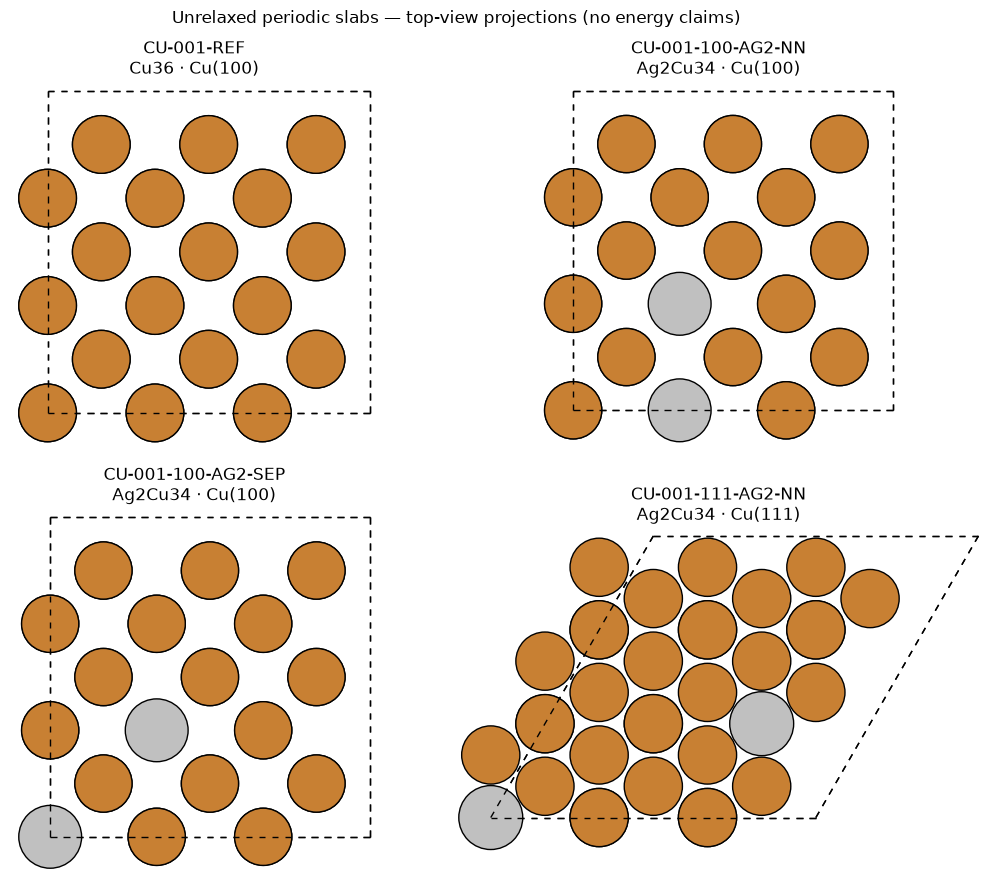

Visual inspection material displayed; human approval NOT assigned


In [7]:
# PSEUDOCODE
# 1. Select representative Cu(100) and Cu(111) structures.
# 2. Plot top-down atomic projections using ASE's atomic plotter.
# 3. Label each structure's identifier, facet and formula.
# 4. Avoid any automatic human-approval flag or output-file modification.

import matplotlib.pyplot as plt
from ase.visualize.plot import plot_atoms

visual_ids = [
    "CU-001-REF",
    "CU-001-100-AG2-NN",
    "CU-001-100-AG2-SEP",
    "CU-001-111-AG2-NN",
]
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, candidate_id in zip(axes.flat, visual_ids):
    atoms = structures[candidate_id]
    plot_atoms(atoms, ax=ax, rotation="0x,0y,0z", radii=0.52)
    ax.set_title(f"{candidate_id}\n{atoms.get_chemical_formula()} · Cu({atoms.info['facet']})")
    ax.set_axis_off()
fig.suptitle("Unrelaxed periodic slabs — top-view projections (no energy claims)")
plt.tight_layout()
plt.show()
print("Visual inspection material displayed; human approval NOT assigned")

## 4.8 — Reproducible geometry fingerprints and provenance registry

**Why:** A stable identifier alone cannot prove that geometry has not changed. We calculate a SHA-256 fingerprint from rounded atomic coordinates, atomic numbers, cell vectors, tags and periodic-boundary flags, alongside a human-readable specification.

**Provenance fields:** `candidate_id`, Cu facet, formula, Ag count and layer placement, periodic Ag–Ag spacing when applicable, source construction method, model status, and SHA-256. Units are explicit.

**Do not confuse:** A geometry hash is a reproducibility fingerprint, **not** a measure of chemical validity or energy convergence.

In [8]:
# PSEUDOCODE
# 1. Serialize only deterministic structural fields, not transient ASE metadata.
# 2. Hash the atomic numbers, tags, positions, cell and PBC.
# 3. Create a concise per-candidate data registry with geometry descriptors.
# 4. Explicitly mark geometry unrelaxed and modeling approval false.
# 5. Verify unique fingerprints without saving anything.

def geometry_fingerprint(atoms):
    payload = {
        "atomic_numbers": atoms.get_atomic_numbers().astype(int).tolist(),
        "positions_A": np.round(atoms.positions, 8).tolist(),
        "cell_vectors_A": np.round(atoms.cell.array, 8).tolist(),
        "layer_tags": atoms.get_tags().astype(int).tolist(),
        "periodic_xyz": [bool(v) for v in atoms.pbc],
    }
    canonical = json.dumps(payload, sort_keys=True, separators=(",", ":"))
    return hashlib.sha256(canonical.encode("utf-8")).hexdigest()

registry_rows = []
for candidate_id, atoms in structures.items():
    ag_idx = np.flatnonzero(atoms.get_atomic_numbers() == 47)
    tags = atoms.get_tags()
    ag_top = int(sum(tags[int(i)] == 1 for i in ag_idx))
    ag_sub = int(sum(tags[int(i)] == 2 for i in ag_idx))
    registry_rows.append({
        "campaign_id": CAMPAIGN_ID,
        "candidate_id": candidate_id,
        "facet": atoms.info["facet"],
        "motif": motifs[candidate_id],
        "chemical_formula": atoms.get_chemical_formula(),
        "atom_count": len(atoms),
        "ag_count": int(len(ag_idx)),
        "ag_top_layer_count": ag_top,
        "ag_subsurface_count": ag_sub,
        "top_layer_site_count": 9,
        "ag_top_site_fraction": round(ag_top / 9, 6),
        "ag_ag_minimum_image_distance_A": round(ag_pair_distance(atoms), 6) if len(ag_idx) == 2 else None,
        "lattice_constant_A": SPEC.lattice_constant_angstrom,
        "initial_vacuum_each_side_A": SPEC.vacuum_angstrom,
        "supercell_size": "3x3x4",
        "pbc_xyz": "True,True,False",
        "source_method": "ASE fcc100/fcc111; src/cuselect/structures.py baselines",
        "geometry_status": "unrelaxed",
        "energy_status": "not_computed",
        "selectivity_status": "not_predicted",
        "structure_review_status": "pending_visual_review",
        "approved_for_modeling": False,
        "geometry_sha256": geometry_fingerprint(atoms),
    })

registry = pd.DataFrame(registry_rows)
assert registry["candidate_id"].is_unique
assert registry["geometry_sha256"].is_unique, "Unexpected duplicate atomic geometry"
assert not registry["approved_for_modeling"].any()
assert registry["geometry_status"].eq("unrelaxed").all()

display(registry[[
    "candidate_id", "facet", "motif", "chemical_formula", "ag_top_site_fraction",
    "ag_ag_minimum_image_distance_A", "structure_review_status", "approved_for_modeling"
]])
print("GEOMETRY PROVENANCE REGISTRY: PASSED |", len(registry), "unique fingerprints")
print("Registry is in memory; no files written")

,candidate_id,facet,motif,chemical_formula,ag_top_site_fraction,ag_ag_minimum_image_distance_A,structure_review_status,approved_for_modeling
0,CU-001-REF,100,pure_reference,Cu36,0.000000,NaN,pending_visual_review,False
1,CU-001-AG1,100,top_layer_single_substitution,AgCu35,0.111111,NaN,pending_visual_review,False
2,CU-001-100-AG2-NN,100,top_layer_nearest_pair,Ag2Cu34,0.222222,2.556191,pending_visual_review,False
3,CU-001-100-AG2-SEP,100,top_layer_separated_pair,Ag2Cu34,0.222222,3.615000,pending_visual_review,False
4,CU-001-100-AG1-SUB,100,subsurface_substitution,AgCu35,0.000000,NaN,pending_visual_review,False
5,CU-001-111-REF,111,pure_reference,Cu36,0.000000,NaN,pending_visual_review,False
6,CU-001-111-AG1,111,top_layer_single_substitution,AgCu35,0.111111,NaN,pending_visual_review,False
7,CU-001-111-AG2-NN,111,top_layer_nearest_pair,Ag2Cu34,0.222222,2.556191,pending_visual_review,False


GEOMETRY PROVENANCE REGISTRY: PASSED | 8 unique fingerprints
Registry is in memory; no files written


## 4.9 — Applicability boundary: structural motifs are not published DFT results

Notebook 03 verified six numerical descriptors from a published **Cu(111)-based** calculation, while Notebook 00 started from Cu(100) models. This notebook now also builds **Cu(111) geometries**, but **facet agreement alone does not establish descriptor compatibility**.

For any planned comparison with published calculations, a future researcher must verify the actual atomic configuration, Ag distribution and coverage, adsorbates, reference states, functional, solvation, field, electrode potential, cell dimensions, sampling, and convergence. No published energy is transferred into these structures, and `approved_for_modeling` remains `False`.

**No reaction-energy barrier, DFT adsorption energy, FE, or selectivity label may be inferred from a structure's Ag fraction or facet.**

In [9]:
# PSEUDOCODE
# 1. Verify every candidate is explicitly unrelaxed and unscored.
# 2. Keep the structural library separate from the published DFT candidate table.
# 3. Prevent implicit promotion of geometry into an ML-ready scientific target.
# 4. Print the exact scientific limitations rather than inventing labels.

assert registry["energy_status"].eq("not_computed").all()
assert registry["selectivity_status"].eq("not_predicted").all()
assert registry["structure_review_status"].eq("pending_visual_review").all()
assert not registry["approved_for_modeling"].any()

print("APPLICABILITY / LABEL INTEGRITY: PASSED")
print("Structures generated:", len(registry))
print("Energies calculated here: 0")
print("Selectivities predicted here: 0")
print("Descriptors transferred from P005 source workbook: 0")
print("Structures approved for modeling: 0")

APPLICABILITY / LABEL INTEGRITY: PASSED
Structures generated: 8
Energies calculated here: 0
Selectivities predicted here: 0
Descriptors transferred from P005 source workbook: 0
Structures approved for modeling: 0


## 4.10 — Controlled export of the geometry library (manual opt-in)

**Default behavior:** **No files are written.** First inspect Sections 4.2–4.9, particularly the top-view structures and motif distinctions. Then deliberately set `EXPORT_STRUCTURES = True` below when ready.

If enabled, the notebook creates a **new** output folder under:

`data/processed/04_structures/`

It will write one `.extxyz` per structure, a machine-readable `04_structure_registry.csv`, and a `04_structure_manifest.json`. It checks every `.extxyz` round-trip before making the new folder available. It **refuses to overwrite an existing export**, so Run All is safe after resetting the gate to `False`.

The export never changes `data/references/02_human_reviewed_claims.csv`, the publisher's XLSX, or any Notebook 02 or 03 results. Exporting models does **not** constitute human approval or computational validation.

In [10]:
# PSEUDOCODE
# 1. Keep export disabled until a deliberate human choice is made.
# 2. If enabled, stage all new files in a temporary directory.
# 3. Remove non-serializable ASE cache metadata from export copies only.
# 4. Validate the saved atomic structures against the original in-memory models.
# 5. Refuse overwriting existing structural exports or source evidence.
# 6. Publish only the new structural output folder after all checks pass.

EXPORT_STRUCTURES = False  # Set True only after reviewing Sections 4.2–4.9
export_folder = ROOT / "data" / "processed" / "04_structures"

if not EXPORT_STRUCTURES:
    print("EXPORT GATE: CLOSED — no geometry files written")
    print("Optional export destination:", export_folder)
else:
    import shutil
    import tempfile
    from contextlib import suppress

    assert not export_folder.exists(), (
        "Existing 04_structures directory detected. Refusing overwrite. "
        "Inspect existing results before creating a new version."
    )

    export_folder.parent.mkdir(parents=True, exist_ok=True)
    staging_root = Path(tempfile.mkdtemp(
        prefix=".04_structures_staging_", dir=str(export_folder.parent)
    ))
    staged = staging_root / "04_structures"
    staged.mkdir()
    try:
        for candidate_id, atoms in structures.items():
            safe = atoms.copy()
            # ASE may contain unhashable adsorbate_info; do not write that cache.
            safe.info = {
                "candidate_id": candidate_id,
                "facet": atoms.info["facet"],
                "geometry_status": "unrelaxed",
                "energy_status": "not_computed",
                "selectivity_status": "not_predicted",
            }
            file_path = staged / f"{candidate_id}.extxyz"
            write(file_path, safe, format="extxyz")
            loaded = read(file_path, format="extxyz")
            assert np.array_equal(loaded.numbers, atoms.numbers), candidate_id
            assert np.array_equal(loaded.pbc, atoms.pbc), candidate_id
            assert np.array_equal(loaded.get_tags(), atoms.get_tags()), (
                f"Layer tags lost in EXTXYZ round-trip: {candidate_id}"
            )
            np.testing.assert_allclose(loaded.positions, atoms.positions, atol=1e-7)
            np.testing.assert_allclose(loaded.cell.array, atoms.cell.array, atol=1e-7)
            assert loaded.info["candidate_id"] == candidate_id

        registry.to_csv(staged / "04_structure_registry.csv", index=False)
        manifest = {
            "campaign_id": CAMPAIGN_ID,
            "notebook": "04_Catalyst_Structures",
            "source": "initial geometries generated with ASE; no DFT relaxation",
            "candidate_count": len(registry),
            "geometry_status": "unrelaxed",
            "human_review_status": "pending_visual_review",
            "ml_approved": False,
            "files": [f"{cid}.extxyz" for cid in structures],
            "registry_file": "04_structure_registry.csv",
            "constraints": {
                "lattice_constant_A": SPEC.lattice_constant_angstrom,
                "supercell": list(SPEC.size),
                "initial_vacuum_each_side_A": SPEC.vacuum_angstrom,
                "pbc_xyz": [True, True, False],
            },
        }
        (staged / "04_structure_manifest.json").write_text(
            json.dumps(manifest, indent=2) + "\n", encoding="utf-8"
        )
        assert len(list(staged.glob("*.extxyz"))) == 8
        staged.rename(export_folder)
    finally:
        shutil.rmtree(staging_root, ignore_errors=True)

    print("GEOMETRY EXPORT COMPLETE:", export_folder)
    print("Files: 8 EXTXYZ + registry CSV + manifest JSON")
    print("Published evidence and human-review records not modified")

EXPORT GATE: CLOSED — no geometry files written
Optional export destination: /Users/nsolebna/202609_Ironhack/Week 8/Project 3/CuSelect-AI/data/processed/04_structures


## 4.11 — Export inspection and independent reload

A future notebook must load versioned files, never hidden Jupyter state. If you enabled export in Section 4.10, use this read-only cell to verify that the new directory contains the complete library, metadata and consistent hashes. If export remains disabled, this cell reports that no export is available and does not create one.

In [14]:
# PSEUDOCODE
# 1. Check whether a structural export exists.
# 2. If present, load all eight exported files and their registry.
# 3. Verify atomic symbols, periodicity, layer tags and fingerprints.
# 4. Confirm the manifest does not overclaim scientific readiness.
# 5. Do not write any files or modify the export.

if not export_folder.exists():
    print("EXPORT INSPECTION: SKIPPED — output directory does not exist")
    print("To generate files, set EXPORT_STRUCTURES=True in Section 4.10 and run that cell")
else:
    saved_registry = pd.read_csv(export_folder / "04_structure_registry.csv", dtype=str)
    saved_manifest = json.loads(
        (export_folder / "04_structure_manifest.json").read_text(encoding="utf-8")
    )
    assert len(saved_registry) == 8
    assert saved_manifest["ml_approved"] is False
    assert saved_manifest["candidate_count"] == 8
    assert set(saved_registry["candidate_id"]) == set(structures)
    for candidate_id, atoms in structures.items():
        loaded = read(export_folder / f"{candidate_id}.extxyz", format="extxyz")
        assert np.array_equal(loaded.numbers, atoms.numbers)
        assert np.array_equal(loaded.pbc, atoms.pbc)
        assert np.array_equal(loaded.get_tags(), atoms.get_tags())
        assert geometry_fingerprint(loaded) == geometry_fingerprint(atoms), candidate_id
        recorded_hash = saved_registry.loc[
            saved_registry["candidate_id"].eq(candidate_id), "geometry_sha256"
        ].iloc[0]
        assert recorded_hash == geometry_fingerprint(atoms)
    print("EXPORT INDEPENDENT RELOAD: PASSED (8/8)")
    print("Scientific labeling preserved: unrelaxed; no predicted selectivity")

EXPORT INDEPENDENT RELOAD: PASSED (8/8)
Scientific labeling preserved: unrelaxed; no predicted selectivity


## 4.12 — Scientific findings, limitations, and handoff to Notebook 05

### Established in this notebook

- The two Notebook 00 Cu(100) controls have been reconstructed using the tested project package.
- The structural design space contains eight deterministic Cu(100)/Cu(111) atomic models with 0–2 substitutional Ag atoms.
- Layer-site counts, compositions, periodic boundaries, minimum distances, intended pair spacings and geometry fingerprints are audited.
- Unrelaxed geometry is visibly and machine-readably distinguished from **computed energies** and **catalytic selectivity**.
- Exports can be enabled explicitly; an existing export is not silently overwritten.

### What is **not** established

These structures have **not** undergone relaxation, DFT convergence testing, surface reconstruction, solvation/electrochemical-potential analysis, adsorption calculations, or physical stability assessment. No experimental Cu–Ag sample has been synthesized or characterized here. The presence of a Cu(111) model does not make P005's DFT values automatically applicable. No structure is approved for catalyst performance prediction.

### Notebook 05 — Scientific ML and Baselines

The next stage will assess **what can actually be scored and validated**. Any ML potential or descriptor method must document its domain of applicability and energy/force accuracy. It must not be used to assert ethylene or ethanol FE from unrelaxed Cu–Ag geometry alone. Notebook 05 should consume `data/processed/04_structures/` only **after Section 4.10 is explicitly enabled and 4.11 passes**.

### Completion gate

1. Run all Python cells successfully from a fresh kernel.
2. Inspect top-view plots and review the intended substitution sites.
3. Confirm eight unique deterministic fingerprints and all geometry checks.
4. Deliberately enable and pass the controlled export; verify the eight EXTXYZ round-trips.
5. Re-run project regression tests (`python -m pytest -q` in the **VS Code Terminal**).
6. Commit the notebook and source-code changes deliberately, excluding generated large files and source evidence.

**Research decision:** An atomic-model library is a controlled input for future computational screening, not itself a screen of catalyst activity or selectivity.

In [15]:
# PSEUDOCODE
# 1. Summarize which geometry gates passed in memory.
# 2. Report the exact status of optional disk export.
# 3. Keep scientific predictions, relaxation and human approval as not performed.
# 4. Display a handoff summary without changing files.

notebook04_summary = {
    "campaign_id": CAMPAIGN_ID,
    "notebook": "04_Catalyst_Structures",
    "models_constructed": len(structures),
    "facets": sorted(set(registry["facet"])),
    "reference_models": 2,
    "geometry_fingerprints_unique": bool(registry["geometry_sha256"].is_unique),
    "composition_and_layer_checks": "passed",
    "periodic_geometry_checks": "passed",
    "energy_calculations_performed": 0,
    "faradaic_efficiencies_predicted": 0,
    "modeling_approved": False,
    "human_visual_review": "pending",
    "export_present": export_folder.exists(),
    "export_directory": str(export_folder.relative_to(ROOT)),
    "next_notebook": "05_Scientific_ML_and_Baselines",
}
print("NOTEBOOK 04 — STRUCTURE LIBRARY SUMMARY")
print(json.dumps(notebook04_summary, indent=2, ensure_ascii=False))
print("\nNo scientific performance or stability claims generated")

NOTEBOOK 04 — STRUCTURE LIBRARY SUMMARY
{
  "campaign_id": "CU-001",
  "notebook": "04_Catalyst_Structures",
  "models_constructed": 8,
  "facets": [
    "100",
    "111"
  ],
  "reference_models": 2,
  "geometry_fingerprints_unique": true,
  "composition_and_layer_checks": "passed",
  "periodic_geometry_checks": "passed",
  "energy_calculations_performed": 0,
  "faradaic_efficiencies_predicted": 0,
  "modeling_approved": false,
  "human_visual_review": "pending",
  "export_present": true,
  "export_directory": "data/processed/04_structures",
  "next_notebook": "05_Scientific_ML_and_Baselines"
}

No scientific performance or stability claims generated
